In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [47]:
df_final_demo = pd.read_csv("./df_final_demo_clean.csv")
df_final_web_data = pd.read_csv("./df_final_web_data_clean.csv")
df = pd.read_csv("./df_v1.csv")

In [48]:
df.head()

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth,Variation,number_of_visits,number_of_events,completed_visits,average_visit_duration_seconds
0,836976,6,73,60.5,U,2,45105.30,6,9,Test,2,11,0,1017.0
1,2304905,7,94,58.0,U,2,110860.30,6,9,Control,1,6,0,295.0
2,1439522,5,64,32.0,U,2,52467.79,6,9,Test,2,5,0,58.5
3,1562045,16,198,49.0,M,2,67454.65,3,6,Test,1,1,0,0.0
4,5126305,12,145,33.0,F,2,103671.75,0,3,Control,1,1,0,0.0


In [52]:
df_final_web_data.head()

,client_id,visitor_id,visit_id,process_step,date_time,month,year,time,day
0,3561384,451664975_1722933822,100012776_37918976071_457913,4,2017-04-26 13:22:17,4,2017,13:22:17,26
1,3561384,451664975_1722933822,100012776_37918976071_457913,4,2017-04-26 13:23:09,4,2017,13:23:09,26
2,9056452,306992881_89423906595,1000165_4190026492_760066,0,2017-06-04 01:07:29,6,2017,01:07:29,4
3,9056452,306992881_89423906595,1000165_4190026492_760066,1,2017-06-04 01:07:32,6,2017,01:07:32,4
4,9056452,306992881_89423906595,1000165_4190026492_760066,2,2017-06-04 01:07:56,6,2017,01:07:56,4


In [53]:
df_final_web_data = df_final_web_data.merge(
    df[["client_id", "Variation"]], on="client_id", how="inner"
)

In [54]:
df.groupby("Variation")["average_visit_duration_seconds"].describe()

,count,mean,std,min,25%,50%,75%,max
Variation,,,,,,,,
Control,23526.0,293.764519,443.095936,0.0,85.0,188.0,353.0,22895.0
Test,26961.0,328.362727,521.620956,0.0,100.0,193.0,371.0,18015.0


In [55]:
df.groupby("Variation")["completed_visits"].value_counts()

Variation  completed_visits
Control    0                   23526
Test       0                   26961
Name: count, dtype: int64

Takeaway: The distributions are heavily right-skewed by extreme outliers. This confirms that the median (50%) is a much more reliable metric for representing the "typical" user experience than the mean. The typical user in the Test group spent only 5 seconds longer overall than in the Control group.

<Axes: xlabel='Variation', ylabel='average_visit_duration_seconds'>

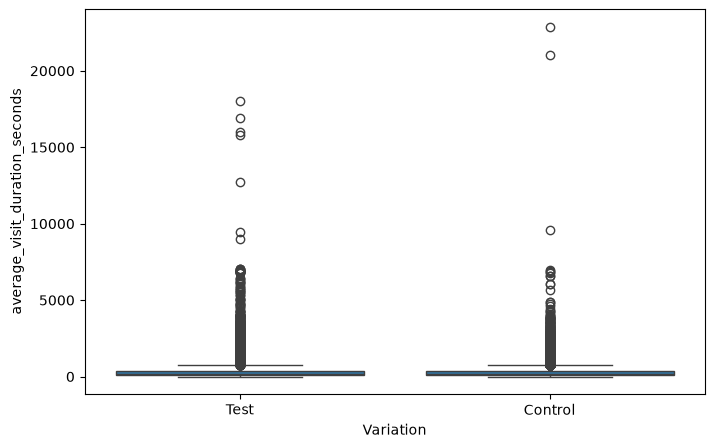

In [56]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Variation",
    y="average_visit_duration_seconds",
)

<Axes: xlabel='Variation', ylabel='average_visit_duration_seconds'>

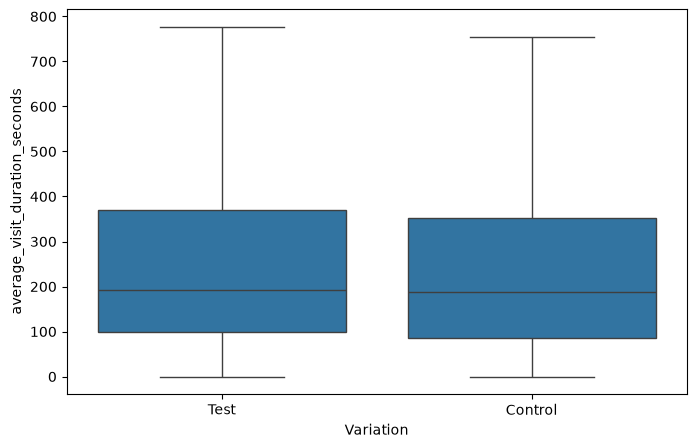

In [57]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Variation",
    y="average_visit_duration_seconds",
    showfliers=False,  # hides the extreme individual outlier dots
)

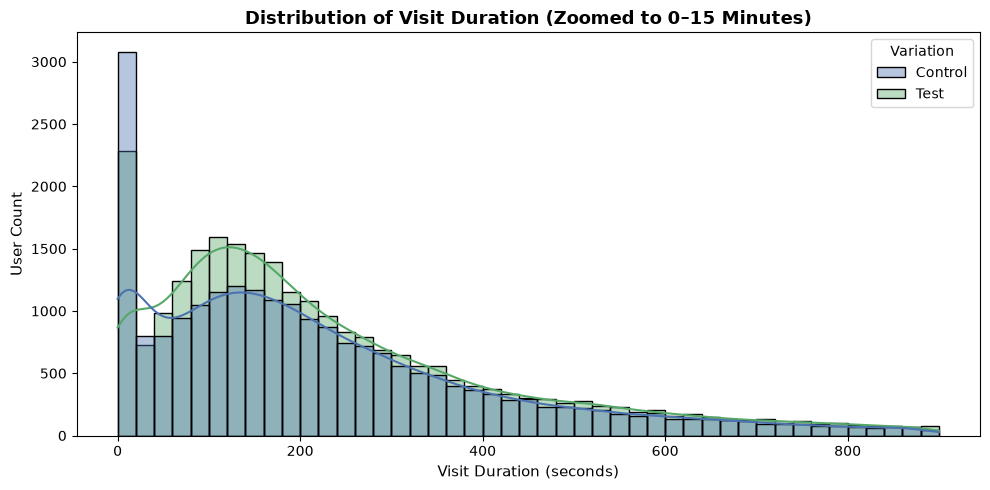

In [58]:
plt.figure(figsize=(10, 5))

# Filter to sessions <= 900s to visualize the shape clearly
sns.histplot(
    data=df[df['average_visit_duration_seconds'] <= 900],
    x='average_visit_duration_seconds',
    hue='Variation',
    kde=True,
    bins=45,
    palette=['#4C72B0', '#55A868'],
    alpha=0.4
)

plt.title('Distribution of Visit Duration (Zoomed to 0–15 Minutes)', fontsize=13, fontweight='bold')
plt.xlabel('Visit Duration (seconds)', fontsize=11)
plt.ylabel('User Count', fontsize=11)
plt.tight_layout()
plt.show()

In [59]:
df_final_web_data = df_final_web_data.sort_values(by=['visit_id', 'date_time']).reset_index(drop=True)
df_final_web_data["date_time"] = pd.to_datetime(df_final_web_data["date_time"])

In [60]:
# 1. Sort visits chronologically
df_final_web_data = df_final_web_data.sort_values(
    by=["visit_id", "date_time"]
).reset_index(drop=True)

# 2. Get the next step's timestamp within the same visit
df_final_web_data["next_date_time"] = df_final_web_data.groupby("visit_id")[
    "date_time"
].shift(-1)

# 3. Calculate step duration in seconds
df_final_web_data["step_duration_seconds"] = (
    df_final_web_data["next_date_time"] - df_final_web_data["date_time"]
).dt.total_seconds()

In [61]:
df_final_web_data

,client_id,visitor_id,visit_id,process_step,date_time,month,year,time,day,Variation,next_date_time,step_duration_seconds
0,3561384,451664975_1722933822,100012776_37918976071_457913,4,2017-04-26 13:22:17,4,2017,13:22:17,26,Test,2017-04-26 13:23:09,52.0
1,3561384,451664975_1722933822,100012776_37918976071_457913,4,2017-04-26 13:23:09,4,2017,13:23:09,26,Test,NaT,NaN
2,7338123,612065484_94198474375,100019538_17884295066_43909,0,2017-04-09 16:20:56,4,2017,16:20:56,9,Test,2017-04-09 16:21:12,16.0
3,7338123,612065484_94198474375,100019538_17884295066_43909,1,2017-04-09 16:21:12,4,2017,16:21:12,9,Test,2017-04-09 16:21:21,9.0
4,7338123,612065484_94198474375,100019538_17884295066_43909,2,2017-04-09 16:21:21,4,2017,16:21:21,9,Test,2017-04-09 16:21:35,14.0
...,...,...,...,...,...,...,...,...,...,...,...,...
321190,6627522,730634087_44272418812,999988789_76411676596_272843,0,2017-04-21 23:49:11,4,2017,23:49:11,21,Test,2017-04-21 23:49:22,11.0
321191,6627522,730634087_44272418812,999988789_76411676596_272843,1,2017-04-21 23:49:22,4,2017,23:49:22,21,Test,2017-04-21 23:50:16,54.0
321192,6627522,730634087_44272418812,999988789_76411676596_272843,2,2017-04-21 23:50:16,4,2017,23:50:16,21,Test,2017-04-21 23:51:00,44.0
321193,6627522,730634087_44272418812,999988789_76411676596_272843,1,2017-04-21 23:51:00,4,2017,23:51:00,21,Test,2017-04-21 23:51:09,9.0


In [62]:
df_final_web_data[
    [
        "visit_id",
        "process_step",
        "date_time",
        "next_date_time",
        "step_duration_seconds",
    ]
].head(6)

,visit_id,process_step,date_time,next_date_time,step_duration_seconds
0,100012776_37918976071_457913,4,2017-04-26 13:22:17,2017-04-26 13:23:09,52.0
1,100012776_37918976071_457913,4,2017-04-26 13:23:09,NaT,NaN
2,100019538_17884295066_43909,0,2017-04-09 16:20:56,2017-04-09 16:21:12,16.0
3,100019538_17884295066_43909,1,2017-04-09 16:21:12,2017-04-09 16:21:21,9.0
4,100019538_17884295066_43909,2,2017-04-09 16:21:21,2017-04-09 16:21:35,14.0
5,100019538_17884295066_43909,1,2017-04-09 16:21:35,2017-04-09 16:21:41,6.0


In [63]:
step_time_summary = (df_final_web_data.groupby(["process_step", "Variation"])["step_duration_seconds"].agg(median_sec="median", mean_sec="mean", count="count").reset_index())

step_time_summary

,process_step,Variation,median_sec,mean_sec,count
0,0,Control,18.0,62.896677,37949
1,0,Test,14.0,60.557650,47008
2,1,Control,20.0,50.305041,26167
3,1,Test,27.0,60.580369,35617
4,2,Control,64.0,91.626863,24420
5,2,Test,61.0,88.614202,29658
6,3,Control,71.0,135.444563,20537
7,3,Test,57.0,128.937401,24106
8,4,Control,41.0,164.092802,2209
9,4,Test,91.0,243.120249,4341


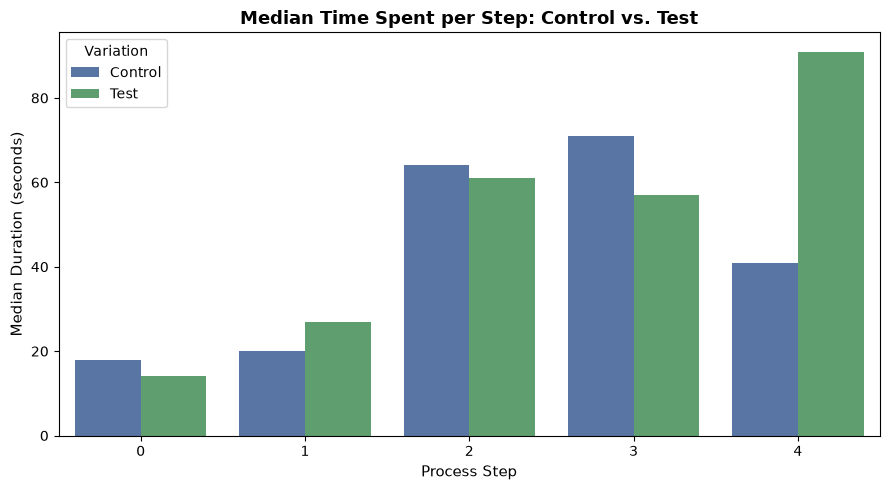

In [64]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=step_time_summary,
    x='process_step',
    y='median_sec',
    hue='Variation',
    palette=['#4C72B0', '#55A868']
)

plt.title('Median Time Spent per Step: Control vs. Test', fontsize=13, fontweight='bold')
plt.xlabel('Process Step', fontsize=11)
plt.ylabel('Median Duration (seconds)', fontsize=11)
plt.legend(title='Variation')
plt.tight_layout()
plt.show()

- Significant Efficiency Gains in Later Stages: The Test group moves through the critical decision-making steps faster, saving 3 seconds on Step 2 (61.0s vs. 64.0s) and 14 seconds on Step 3 (57.0s vs. 71.0s). This indicates that the redesigned UI and in-context prompts help clarify complex choices right before confirmation.
- Quicker Initial Engagement: Users in the Test group take less time to initiate the process on Step 0 (14.0s vs. 18.0s in Control), suggesting the new entry page is cleaner and more actionable.
- Potential Friction Point at Step 1: Step 1 is the only standard funnel step where the Test group takes longer than Control (27.0s vs. 20.0s, a 35% increase). This flags Step 1 as a specific area for UX review: are users reading new informational prompts, or experiencing confusion?
- Heavy Right Skew Across Both Variations: Mean durations across all steps are roughly double the median values (e.g., Step 3 Test mean is ~128.9s vs. median 57.0s). Outliers distort the arithmetic mean, making the median the appropriate metric to represent typical client behavior.
- Confirmation Page Artifacts: Durations recorded on Step 4 represent only a small fraction of users (4,341 in Test, 2,209 in Control) who stayed on the final screen before navigating elsewhere. The higher median time on Step 4 for Test (91.0s vs. 41.0s) suggests users are reviewing details more thoroughly or lingering on the final receipt screen before closing the tab. 

- Step 1 Duration HypothesisContext from the Summary Table:Control Median: $20.0\text{ seconds}$   Test Median: $27.0\text{ seconds}$
- Step 1 is the only step in the sequence where the Test group was substantially slower (+35% increase in median duration).
- $H_0$ (Null Hypothesis):There is no difference in the distribution of time spent on Step 1 between the Control and Test groups ($M_{\text{Test}} = M_{\text{Control}}$).
- $H_1$ (Alternative Hypothesis):Clients in the Test group spend significantly more time on Step 1 than clients in the Control group ($M_{\text{Test}} > M_{\text{Control}}$).

In [65]:
df_final_web_data.groupby("Variation")["process_step"].value_counts()

Variation  process_step
Control    0               47589
           1               29657
           2               25877
           3               22787
           4               17498
Test       0               56452
           1               38753
           2               30978
           3               25888
           4               25716
Name: count, dtype: int64